# What we tried, why, and what it means for Atok

This notebook explains every experiment run for the carrot / cabbage / potato classifier: what the data looks like, how it was
split into **train, validation and test**, why each setting and month was chosen, what each experiment changed,
and what the results mean for mapping **Atok, Benguet**.

It starts with the big picture and then goes step by step. Every number and chart is read from the saved run
files of 22 November 2026 when you run the notebook; nothing is typed in by hand.

**Two things to keep in mind throughout**

- **Nothing here measures accuracy in Atok.** No dated, labelled Atok fields exist yet. The Atok sections show
  what the models *would* predict and whether that is plausible. The January 2027 field visit is the real test.
- **The external test is no longer "fresh".** Those parcels have been looked at while the project evolved, so
  test scores describe this benchmark, not a guaranteed result elsewhere.

In [1]:
from pathlib import Path
import csv
import json
import sys

root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").is_file())
for path in (root / "src", root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from crop_pipeline.analysis_workflow import resolve_stage_pointer

# Colours used everywhere: one per crop, one per window, grey for "baseline / reference".
CROP = {"carrot": "#eb6834", "cabbage": "#1baf7a", "potato": "#2a78d6"}
BLUE, ORANGE, GREEN, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a9a8a3", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e7e6e1",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "font.size": 10})

def read_csv(path):
    with Path(path).open(newline="", encoding="utf-8") as stream:
        return list(csv.DictReader(stream))

def label_bars(ax, bars, fmt="{:.2f}", horizontal=False, inside=False):
    """Value labels just past each bar (or inside its top when ``inside``); spacing scales with the data."""
    values = [b.get_width() if horizontal else b.get_height() for b in bars]
    gap = 0.015 * max(values) if values else 0
    for bar, value in zip(bars, values):
        if horizontal:
            ax.text(value + gap, bar.get_y() + bar.get_height() / 2, fmt.format(value), va="center", fontsize=9, color=INK)
        elif inside:
            ax.text(bar.get_x() + bar.get_width() / 2, value / 2, fmt.format(value), ha="center", va="center",
                    fontsize=10, color="white", fontweight="bold")
        else:
            ax.text(bar.get_x() + bar.get_width() / 2, value + gap, fmt.format(value), ha="center", fontsize=9, color=INK)

# The runs this notebook reads (current stage pointers, plus the experiment folders of 22 November 2026).
features = resolve_stage_pointer(root / "pipeline_outputs/preprocessing/current_features.json").parent
training = resolve_stage_pointer(root / "pipeline_outputs/training/current_models.json").parent.parent
testing = resolve_stage_pointer(root / "pipeline_outputs/testing/current_scores.json").parent
batch2, batch3 = testing.parent / f"{testing.name}_batch2", testing.parent / f"{testing.name}_batch3"
experiments = root / "pipeline_outputs/experiments/rerun_20261122"
mixed = root / "pipeline_outputs/mixed_training/weighted_20261122"
settings = json.loads((root / "settings.local.json").read_text())
paoay = (root / settings.get("report_root", "./data/pipeline_work/inventory")).resolve().parent / "paoay"
land = resolve_stage_pointer(paoay / "land_activity/land_activity_stage.json").parent
for name, path in [("features", features), ("training", training), ("testing", testing), ("experiments", experiments),
                   ("mixed training", mixed), ("Atok land activity", land)]:
    print(f"{name:20} {path.relative_to(root)}")

features             sen4agrinet_work/analysis/external/external_epbjofk7
training             pipeline_outputs/training/run_79cc09f61c3e
testing              pipeline_outputs/testing/run_78548ef86423
experiments          pipeline_outputs/experiments/rerun_20261122
mixed training       pipeline_outputs/mixed_training/weighted_20261122
Atok land activity   sen4agrinet_work/paoay/land_activity/bundles/7a451e1678ff1cf5b266


## 1. The big picture

**The goal:** a map of carrot, cabbage and potato fields in Atok from Sentinel-2 satellite images.

**The problem:** a classifier learns from labelled examples, and there are no labelled fields in Atok yet.
So the plan is:

1. **Learn** from labelled fields elsewhere: European parcels from Sen4AgriNet, FranceCrops and EuroCrops, where
   farmers declared what they grew.
2. **Check** the model on labelled fields from *other* countries it never trained on: CropHarvest JECAM sites in
   Madagascar and Senegal (the main test), plus carrot in California, cabbage in Denmark and fields in France,
   Réunion and Martinique.
3. **Apply** the frozen model to Atok, and judge the map with whatever local context exists (farmer calendars,
   land-use maps, provincial statistics) until field observations arrive.

Step 2 is the key question: *does what the model learned in Europe still work somewhere else?* If it fails in
Madagascar and Senegal, there is little reason to trust it in Atok.

```
 Europe (labels)  ──train──▶  Model  ──test──▶  Madagascar, Senegal, … (labels, never trained on)
                                 │
                                 └──apply──▶  Atok (no labels yet: plausibility checks only)
```

## 2. What the data looks like

Before any model, here is the raw material: where the labelled fields are, what one field looks like from space
through a year, what each crop's signal looks like, and what Atok looks like in the same images.

### Where the labelled fields are

Each dot is one labelled field (its first sampled pixel). Blue fields are used for learning (train and validation);
orange fields are only used to test. Atok is the star.

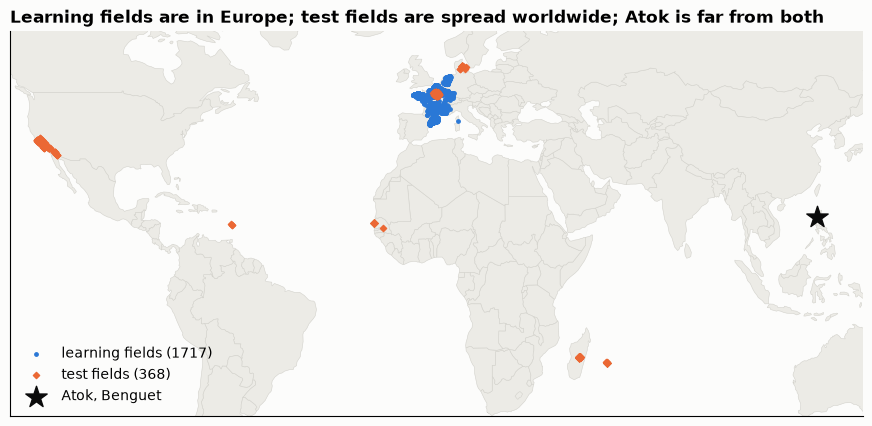

In [2]:
from shapely.geometry import shape
from pyproj import Transformer

# Country outlines: Natural Earth low-resolution (public domain), saved in notebooks/assets.
basemap = [shape(f["geometry"]) for f in json.loads((root / "notebooks/assets/world_lowres.geojson").read_text())["features"]]

def draw_land(ax):
    for geometry in basemap:
        for polygon in getattr(geometry, "geoms", [geometry]):
            x, y = polygon.exterior.xy
            ax.fill(x, y, color="#ecebe6", edgecolor="#d3d2cc", lw=.4, zorder=0)

def field_points(path, cohort="fixed_full"):
    """One (lon, lat, crop, partition) per field, from the first pixel of each field."""
    first = {}
    for row in json.loads(Path(path).read_text())["rows"][cohort]:
        first.setdefault(row["partition_group"], row)
    by_crs = {}
    for row in first.values():
        by_crs.setdefault(row["source_crs"], []).append(row)
    points = []
    for crs, rows in by_crs.items():
        lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform([r["x"] for r in rows], [r["y"] for r in rows])
        points += [(a, b, r["crop"], r["partition"], r.get("test_cohort") or "") for a, b, r in zip(lon, lat, rows)]
    return points

development_points = field_points(features / "features_development.json")
test_points = field_points(features / "features_test.json")
ATOK = (120.71, 16.58)

fig, ax = plt.subplots(figsize=(11, 5))
draw_land(ax)
ax.scatter([p[0] for p in development_points], [p[1] for p in development_points], s=6, color=BLUE, label=f"learning fields ({len(development_points)})")
ax.scatter([p[0] for p in test_points], [p[1] for p in test_points], s=10, color=ORANGE, marker="D", label=f"test fields ({len(test_points)})")
ax.scatter(*ATOK, s=260, marker="*", color="#0b0b0b", label="Atok, Benguet", zorder=5)
ax.set_xlim(-130, 135); ax.set_ylim(-35, 65)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("Learning fields are in Europe; test fields are spread worldwide; Atok is far from both")
ax.legend(frameon=False, loc="lower left")
plt.show()

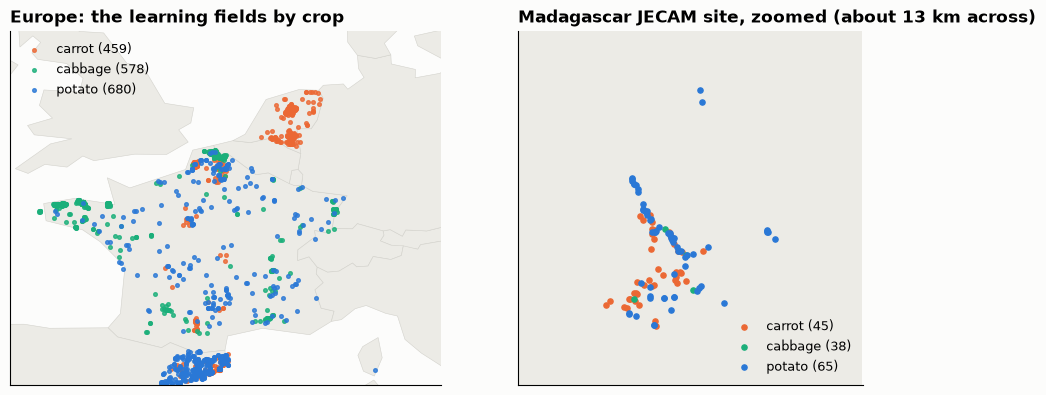

JECAM test fields by country: {'Madagascar': 114, 'Senegal': 34}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
draw_land(ax)
for crop in CROP:
    chosen = [p for p in development_points if p[2] == crop]
    ax.scatter([p[0] for p in chosen], [p[1] for p in chosen], s=7, color=CROP[crop], label=f"{crop} ({len(chosen)})", alpha=.8)
ax.set_xlim(-6, 12); ax.set_ylim(41, 56); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("Europe: the learning fields by crop")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax = axes[1]
draw_land(ax)
jecam = [p for p in test_points if p[4] == "jecam"]
for crop in CROP:
    chosen = [p for p in jecam if p[2] == crop]
    ax.scatter([p[0] for p in chosen], [p[1] for p in chosen], s=14, color=CROP[crop], label=f"{crop} ({len(chosen)})")
madagascar = [p for p in jecam if p[1] < 0]
lon0, lon1 = min(p[0] for p in madagascar), max(p[0] for p in madagascar)
lat0, lat1 = min(p[1] for p in madagascar), max(p[1] for p in madagascar)
pad = .25 * max(lon1 - lon0, lat1 - lat0, .05)
ax.set_xlim(lon0 - pad, lon1 + pad); ax.set_ylim(lat0 - pad, lat1 + pad); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title(f"Madagascar JECAM site, zoomed (about {111 * (lon1 - lon0):.0f} km across)")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()
print("JECAM test fields by country:", {"Madagascar": sum(p[1] < 0 for p in jecam), "Senegal": sum(p[1] > 0 for p in jecam)})

### One field from space, through a year

These are real Sentinel-2 pixels of one *typical* training field per crop (the field whose May–August greenness
is closest to its crop's median), shown in natural colour for the first half of each month. Only the field's own sampled pixels are stored, so the field appears as a small patch; grey means no
clear view that half-month (cloud, shadow or no image). This is why the pipeline works in half-months and needs
80% of a field to be clear.

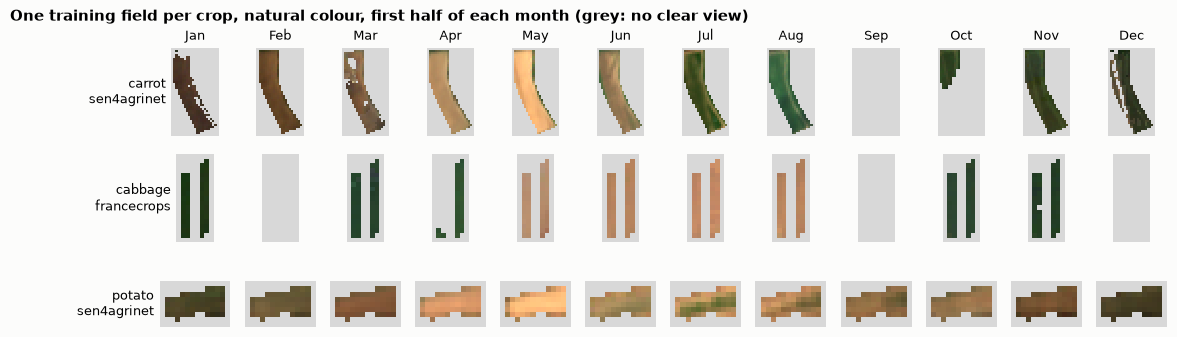

carrot   sen4agrinet FR 2019: 321 pixels
cabbage  francecrops FR 2022: 60 pixels
potato   sen4agrinet ES 2019: 60 pixels


In [4]:
import rasterio

quality_handoff = json.loads((features / "quality.json").read_text())
regions = {r["properties"]["fragment_id"]: r["properties"] for r in quality_handoff["regions"]}
index = {}
for source in quality_handoff["sources"]:
    if source["source_family"] in ("francecrops", "sen4agrinet", "eurocrops"):
        index.update(source["annual_tif_index"])

def read_field(fragment):
    with rasterio.open(index[fragment]["path"]) as image:
        cube = image.read().astype(float)
        names = image.descriptions
    cube[cube == -9999] = np.nan
    stride = len(names) // 24  # 7 values per half-month, or 10 with extra observation counts
    bands = [n.split("__", 1)[1] for n in names[:stride]]
    return cube.reshape(24, stride, *cube.shape[1:]), bands, names

train_rows = [r for r in json.loads((features / "features_development.json").read_text())["rows"]["fixed_full"]
              if r["partition"] == "train"]
ndvi_bins = [f"bin_{k:02d}_NDVI" for k in range(1, 9)]

def pick_field(crop, minimum_pixels=30):
    """A typical training field: its May–August NDVI curve is closest to the crop's median curve."""
    rows = [r for r in train_rows if r["crop"] == crop]
    median = np.median([[r[b] for b in ndvi_bins] for r in rows], axis=0)
    by_field = {}
    for r in rows:
        by_field.setdefault(r["fragment_id"], []).append([r[b] for b in ndvi_bins])
    ranked = sorted(by_field, key=lambda f: float(np.abs(np.mean(by_field[f], axis=0) - median).mean()))
    for fragment in ranked:
        if fragment in index:
            with rasterio.open(index[fragment]["path"]) as image:
                count = int((image.read(1) != -9999).sum())
            if count >= minimum_pixels:
                return fragment, count, regions.get(fragment, {})
    raise ValueError(f"No stored field image for {crop}")

fields = {crop: pick_field(crop) for crop in CROP}
month_names = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()
fig, axes = plt.subplots(3, 12, figsize=(13, 3.9))
cubes = {}
for r, crop in enumerate(CROP):
    fragment, count, props = fields[crop]
    cube, bands, _ = read_field(fragment)
    cubes[crop] = (cube, bands)
    rows, cols = np.where(np.isfinite(cube[0, 0]) | np.isfinite(cube[12, 0]))
    window = (slice(max(rows.min() - 1, 0), rows.max() + 2), slice(max(cols.min() - 1, 0), cols.max() + 2))
    for m in range(12):
        ax = axes[r, m]
        half = cube[2 * m]
        rgb = np.stack([half[bands.index(b)] for b in ("B4", "B3", "B2")], axis=-1) / 2500
        clear = half[bands.index("clear_count")] > 0
        image = np.where(np.isfinite(rgb).all(axis=-1, keepdims=True) & clear[..., None], np.clip(rgb, 0, 1), 0.85)
        ax.imshow(image[window], interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if r == 0:
            ax.set_title(month_names[m], fontsize=9, fontweight="normal", loc="center")
    axes[r, 0].set_ylabel(f"{crop}\n{props['source_dataset'] if 'source_dataset' in props else ''}", fontsize=9,
                          rotation=0, ha="right", va="center")
fig.suptitle("One training field per crop, natural colour, first half of each month (grey: no clear view)",
             x=.01, ha="left", fontweight="bold", fontsize=11)
plt.show()
for crop, (fragment, count, props) in fields.items():
    print(f"{crop:8} {props.get('source_dataset', '')} {props.get('country', '')} {props.get('year', '')}: {count} pixels")

The same three fields as a greenness curve (**NDVI**, from the red and near-infrared bands; bare soil is near 0.1–0.2,
a full green canopy above 0.7). Each dot is the field's median over its pixels in one half-month; gaps are
cloudy half-months. The shaded band is the fixed May–August window the window models read.

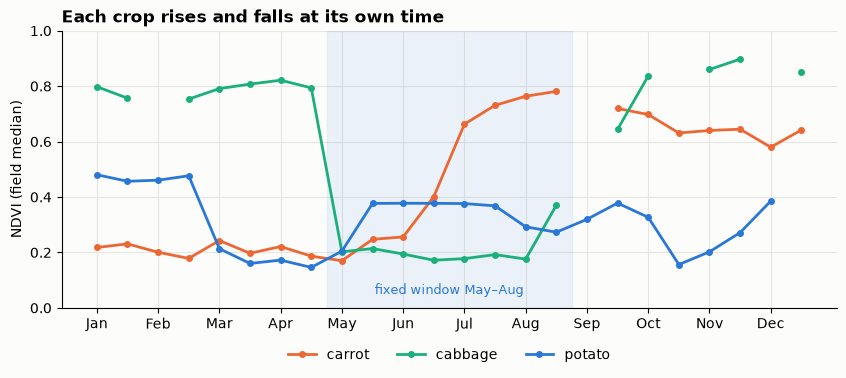

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for crop, (cube, bands) in cubes.items():
    red, nir = cube[:, bands.index("B4")], cube[:, bands.index("B8")]
    clear = cube[:, bands.index("clear_count")] > 0
    with np.errstate(invalid="ignore", divide="ignore"):
        ndvi = np.where(clear, (nir - red) / (nir + red), np.nan)
    values = np.array([np.nanmedian(ndvi[k]) if np.isfinite(ndvi[k]).any() else np.nan for k in range(24)])
    ax.plot(np.arange(24), values, marker="o", ms=4, lw=2, color=CROP[crop], label=crop)
ax.axvspan(7.5, 15.5, color=BLUE, alpha=.08)
ax.text(11.5, .05, "fixed window May–Aug", ha="center", fontsize=9, color=BLUE)
ax.set_xticks(np.arange(0, 24, 2), month_names)
ax.set_ylim(0, 1)
ax.set_ylabel("NDVI (field median)")
ax.set_title("Each crop rises and falls at its own time")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3)
plt.show()

### What the model learns from: the average crop curve

Across all training fields, this is the median greenness of each crop in the eight half-months the model reads
(shaded: the middle half of the fields). The fixed window reads the same calendar dates for every field; the
aligned window reads the eight half-months after each field's own green-up. The model separates crops by the
differences between these curves, using all nine values per half-month, not only NDVI.

Notice the cabbage curve in the fixed window: European training cabbage is still mostly bare in May–July (median
NDVI about 0.2) and only greens up in August, because much of it is planted for an autumn or winter harvest. So
the fixed model largely learns "cabbage = bare soil in early summer", which is one reason it struggles where
cabbage grows at other times, as in Atok.

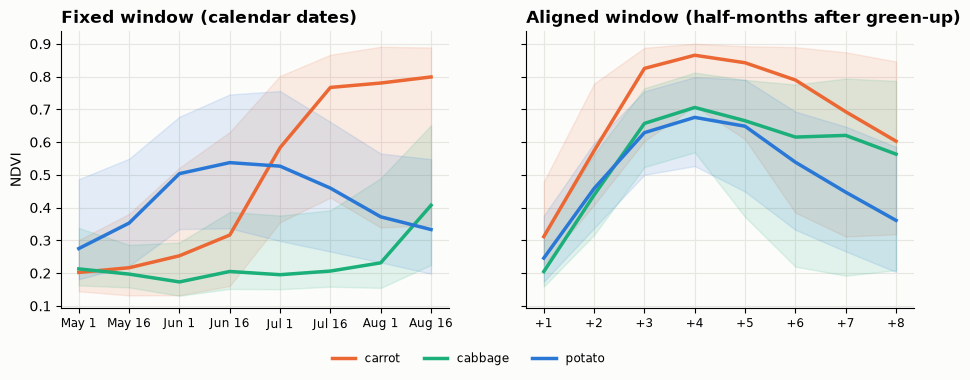

In [6]:
development = json.loads((features / "features_development.json").read_text())["rows"]
bins = [f"bin_{k:02d}_NDVI" for k in range(1, 9)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, cohort, ticks, title in (
        (axes[0], "fixed_full", ["May 1", "May 16", "Jun 1", "Jun 16", "Jul 1", "Jul 16", "Aug 1", "Aug 16"], "Fixed window (calendar dates)"),
        (axes[1], "aligned_full", [f"+{k}" for k in range(1, 9)], "Aligned window (half-months after green-up)")):
    rows = [r for r in development[cohort] if r["partition"] == "train"]
    for crop in CROP:
        values = np.array([[r[b] for b in bins] for r in rows if r["crop"] == crop])
        q25, median, q75 = np.percentile(values, [25, 50, 75], axis=0)
        ax.plot(range(8), median, color=CROP[crop], lw=2.5, label=crop)
        ax.fill_between(range(8), q25, q75, color=CROP[crop], alpha=.12)
    ax.set_xticks(range(8), ticks, fontsize=8.5)
    ax.set_title(title)
axes[0].set_ylabel("NDVI")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(1.05, -.12), ncol=3)
plt.show()

### What Atok looks like in the same images

The Paoay study area in Atok, from the half-month Sentinel-2 composites used for the Atok maps, in false colour
(near-infrared shown as red, so growing vegetation is red; bare soil, roads and buildings show as pale cyan;
white means no clear view). Black outlines are the reference areas from the KMZ notes. The first chart shows how much of the study area each 2024 half-month
composite actually covers; the images then show the clearest dry-season and the cloudiest rainy-season
half-month.

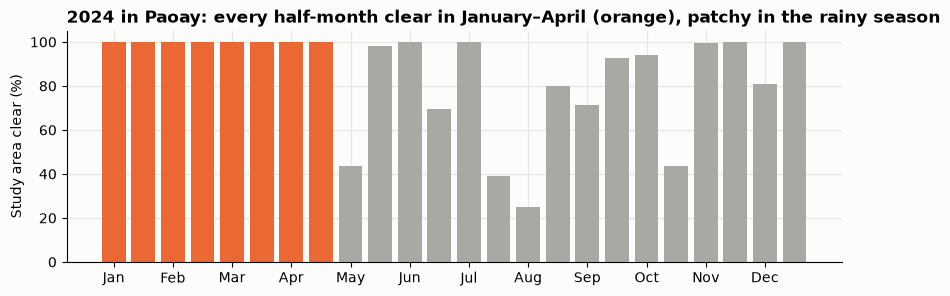

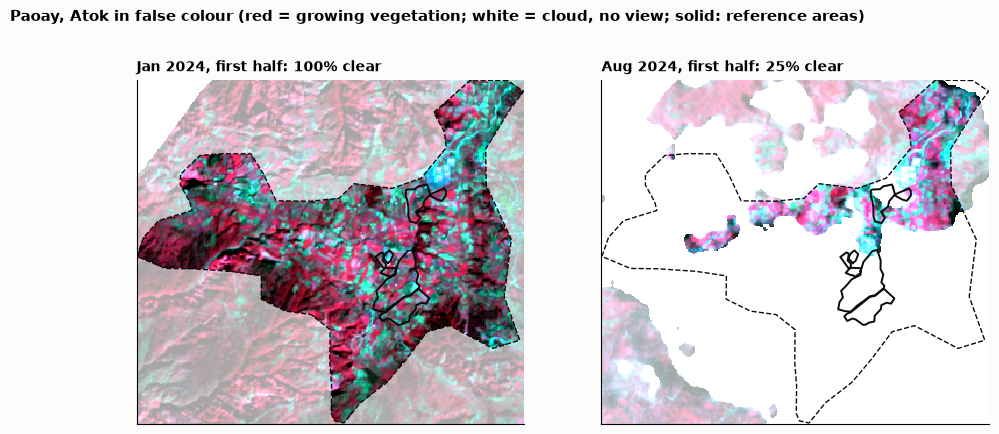

In [7]:
from crop_pipeline.paoay import aligned

kmz_root = (root / settings.get("paoay_kmz_root", "./data/paoay")).resolve()
kmz = [kmz_root / n for n in ("00 - Region of Interest.kmz", "00 - Atok Boundary.kmz", "Crop Area.kmz")]
imagery = Path(settings["atok_imagery_root"]).expanduser()
imagery = imagery if imagery.is_absolute() else (root / imagery).resolve()
with rasterio.open(next(iter(sorted(imagery.glob("*/Sentinel2_CSPlus_*.tif"))))) as source:
    composite_crs = source.crs.to_string()
roi_name = settings.get("paoay_roi_name") or "Region of Interest"
roi, areas, _ = aligned.study_area(kmz, roi_name, [n for n in settings.get("paoay_context_names", []) if n != roi_name], composite_crs)
grid, study_mask = aligned.grid_for(imagery, roi)
col, row, width, height = grid["window"]
transform = rasterio.Affine(*grid["transform"])

def outline(ax, geometry, **style):
    inverse = ~transform
    for polygon in getattr(geometry, "geoms", [geometry]):
        x, y = polygon.exterior.xy
        c, r = zip(*(inverse * p for p in zip(x, y)))
        ax.plot(np.array(c) - .5, np.array(r) - .5, **style)

def read_composite(year, month, half):
    with rasterio.open(imagery / str(year) / f"Sentinel2_CSPlus_{year}_{month:02d}_H{half}.tif") as source:
        data = source.read(window=rasterio.windows.Window(col, row, width, height)).astype(float)
    data[data == -9999] = np.nan
    return data  # bands B3, B4, B5, B8, B11

# Clear share of the study area in every 2024 half-month (a pixel is clear when the composite has a value).
halves = [(m, h) for m in range(1, 13) for h in (1, 2)]
clear_2024 = []
for m, h in halves:
    data = read_composite(2024, m, h)
    clear_2024.append(float((np.isfinite(data).all(axis=0) & study_mask).sum() / study_mask.sum()))
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(24), [100 * c for c in clear_2024], color=[ORANGE if m <= 4 else GREY for m, _ in halves])
ax.set_xticks(range(0, 24, 2), month_names)
ax.set_ylabel("Study area clear (%)")
ax.set_title("2024 in Paoay: every half-month clear in January–April (orange), patchy in the rainy season")
plt.show()

dry = max((i for i, (m, _) in enumerate(halves) if m <= 4), key=lambda i: clear_2024[i])
wet = min((i for i, (m, _) in enumerate(halves) if 6 <= m <= 10), key=lambda i: clear_2024[i])
images = {i: read_composite(2024, *halves[i]) for i in (dry, wet)}
names = ["B3", "B4", "B5", "B8", "B11"]
reference = images[dry]
stretch = {b: np.nanpercentile(reference[names.index(b)][study_mask], [2, 98]) for b in ("B8", "B4", "B3")}

def false_colour(data):
    rgb = np.stack([(data[names.index(b)] - stretch[b][0]) / (stretch[b][1] - stretch[b][0]) for b in ("B8", "B4", "B3")], axis=-1)
    image = np.clip(rgb, 0, 1)
    image[~np.isfinite(rgb).all(axis=-1)] = 1.0  # no clear view
    image[~study_mask] = image[~study_mask] * .35 + .65  # fade outside the study area
    return image

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, i in zip(axes, (dry, wet)):
    m, h = halves[i]
    ax.imshow(false_colour(images[i]), interpolation="nearest")
    outline(ax, roi, color="#0b0b0b", lw=1, ls="--")
    for area in areas:
        outline(ax, area["geometry"], color="#0b0b0b", lw=1.4)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{month_names[m - 1]} 2024, {'first' if h == 1 else 'second'} half: {100 * clear_2024[i]:.0f}% clear", fontsize=10)
fig.suptitle("Paoay, Atok in false colour (red = growing vegetation; white = cloud, no view; solid: reference areas)",
             x=.01, ha="left", fontweight="bold", fontsize=11)
plt.show()

### Land use and land activity in Atok

Two independent context layers for the same area. **Left:** NAMRIA's Existing Land Use map 2023, drawn by people
from high-resolution imagery and local maps, grouped into farmland, forest and built-up land. **Right:** land
activity from 2019–2026 Sentinel-2 (Paoay 06): pixels whose greenness keeps cycling up and down are *active
cropland*. Neither says which crop grows where; they show where a crop map is meaningful.

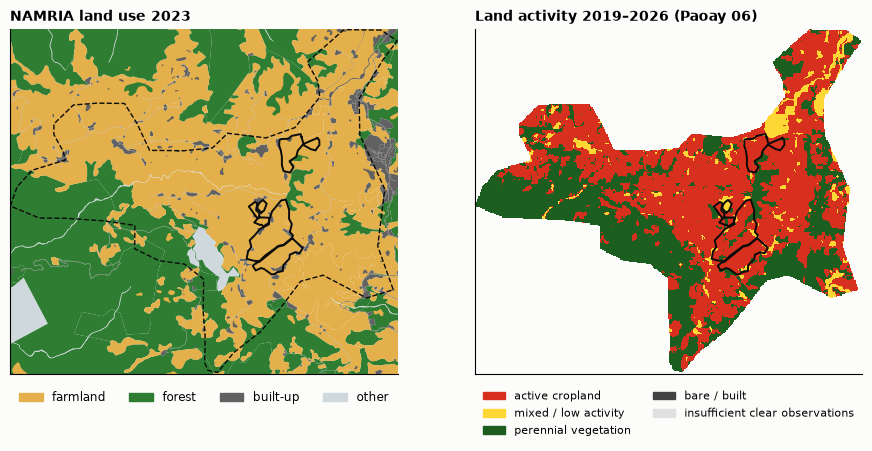

Land activity, share of study pixels: {'active cropland': '56%', 'mixed / low activity': '6%', 'perennial vegetation': '37%', 'bare / built': '0%', 'insufficient clear observations': '0%'}


In [8]:
from crop_pipeline.paoay import area_review, land_activity
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

landuse = area_review.read_landuse((root / settings["atok_landuse_path"]).resolve(), roi.buffer(300).bounds, composite_crs)
groups = {"farmland": set(area_review.FARMLAND_SUBCLASSES),
          "forest": {k for k, v in land_activity.LANDUSE_TYPES.items() if v == "forest"},
          "built-up": {k for k, v in land_activity.LANDUSE_TYPES.items() if v == "built-up"}}
colours = {"farmland": "#e3b04b", "forest": "#2e7d32", "built-up": "#616161", "other": "#cfd8dc"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ax = axes[0]
for sub, geometry in zip(landuse["sub_elu"], landuse.geometry):
    group = next((g for g, members in groups.items() if sub in members), "other")
    for polygon in getattr(geometry, "geoms", [geometry]):
        c, r = zip(*((~transform) * p for p in zip(*polygon.exterior.xy)))
        ax.fill(np.array(c) - .5, np.array(r) - .5, color=colours[group], lw=0)
outline(ax, roi, color="#0b0b0b", lw=1, ls="--")
for area in areas:
    outline(ax, area["geometry"], color="#0b0b0b", lw=1.4)
ax.set_xlim(-.5, width - .5); ax.set_ylim(height - .5, -.5); ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("NAMRIA land use 2023", fontsize=10)
ax.legend(handles=[Patch(color=c, label=g) for g, c in colours.items()], frameon=False, loc="upper center",
          bbox_to_anchor=(.5, -.02), ncol=4, fontsize=8.5)
ax = axes[1]
with rasterio.open(land / "land_activity.tif") as source:
    activity = source.read(1)
classes = sorted(land_activity.LAND_CLASSES)
shown = np.ma.masked_equal(activity, 0)
ax.imshow(shown, cmap=ListedColormap([land_activity.LAND_COLORS[k] for k in classes]), vmin=.5, vmax=len(classes) + .5,
          interpolation="nearest")
for area in areas:
    outline(ax, area["geometry"], color="#0b0b0b", lw=1.4)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_xlim(-.5, width - .5); ax.set_ylim(height - .5, -.5)
ax.set_title("Land activity 2019–2026 (Paoay 06)", fontsize=10)
ax.legend(handles=[Patch(color=land_activity.LAND_COLORS[k], label=land_activity.LAND_CLASSES[k]) for k in classes],
          frameon=False, loc="upper center", bbox_to_anchor=(.5, -.02), ncol=2, fontsize=8)
plt.show()
counts = {land_activity.LAND_CLASSES[k]: int((activity == k).sum()) for k in classes}
total = sum(counts.values())
print("Land activity, share of study pixels:", {k: f"{100 * v / total:.0f}%" for k, v in counts.items()})

## 3. Train, validation and test: what each one is for

| Split | Where from | What it is used for | Why it is kept separate |
| --- | --- | --- | --- |
| **Train** | European development parcels | The model learns from these | — |
| **Validation** | Other European development parcels | Choosing between model settings | If you chose settings on the training parcels, you would just pick whatever memorises them best |
| **Test** | Parcels from other countries | Scoring the final, frozen model once | It answers "does it work elsewhere?"; using it to choose anything would make the answer optimistic |

**How the split is made (step by step)**

1. Every parcel belongs to a *parcel group* (the same field in different years counts as one group).
2. Each group is assigned to train or validation once and **locked**: it never moves between runs. About three
   groups in four go to training (targets: 60 training and 20 validation parcels per crop).
3. Pixels of one field are never split across train and validation. Neighbouring pixels of the same field look
   almost identical, so splitting them would let the model "see" the validation field during training.
4. Pixel locations shared by two different development fields are removed, and test fields that overlap any
   development field are dropped.
5. Up to **20 pixels per parcel** are used, so one big field cannot outweigh many small ones.

The counts below are today's usable parcels for the fixed-window model.

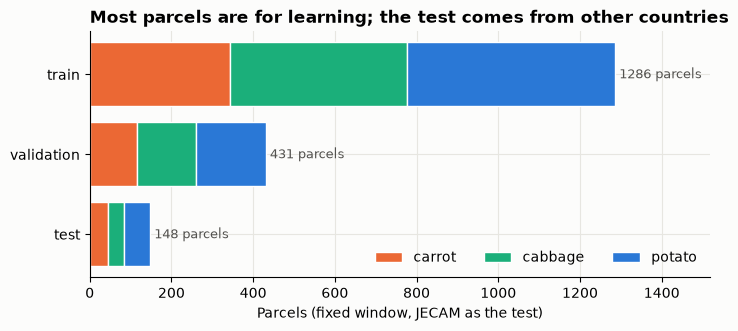

In [9]:
usable = read_csv(features / "usable_samples.csv")
splits = ["train", "validation", "test"]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(3)
for crop in CROP:
    values = np.array([sum(int(r["usable_parcel_groups"]) for r in usable
                           if r["cohort"] == "fixed_full" and r["partition"] == s and r["crop"] == crop) for s in splits])
    ax.barh(splits, values, left=left, color=CROP[crop], label=crop, edgecolor="white")
    left += values
for y, total in enumerate(left):
    ax.text(total + 10, y, f"{int(total)} parcels", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.18)
ax.set_xlabel("Parcels (fixed window, JECAM as the test)")
ax.set_title("Most parcels are for learning; the test comes from other countries")
ax.legend(loc="lower right", ncol=3, frameon=False)
plt.show()

## 4. Why these numbers, months and settings

### What the model looks at: four months in half-month steps

A crop is recognised by how its greenness changes over a season: when it comes up, how fast it grows, when it is
harvested. So each pixel is described as a short time series:

- **Four months**, because carrot, cabbage and potato each take roughly three to four months from planting to
  harvest. A shorter window misses part of the cycle; a longer one mixes in the next crop.
- **Eight half-month bins** (about 15 days each). Sentinel-2 passes every 5 days, but clouds remove many images;
  combining them into half-months leaves enough clear views while still following the crop's growth.
- **Five bands per bin**: green (B3), red (B4), red-edge (B5), near-infrared (B8) and short-wave infrared (B11).
  Healthy leaves reflect near-infrared and absorb red; red-edge follows chlorophyll; short-wave infrared follows
  water in leaves and soil.
- **Four indices per bin**: NDVI (greenness), NDRE (chlorophyll), NDMI (moisture) and SAVI (greenness corrected for
  bare soil between rows). They are ratios of bands, which makes them less sensitive to lighting and atmosphere.
- 8 bins × (5 bands + 4 indices) = **72 numbers per pixel**.
- A half-month counts only if at least **80%** of the field's pixels are clear in it, and all eight must count. The
  model is never given filled-in or guessed values.

### Which four months: fixed and aligned

- **Fixed window: May to August.** This is when European carrot, cabbage and potato grow, so the training
  examples are all at a comparable stage.
- **Aligned window:** four months starting at each field's detected *green-up* (the moment greenness starts to
  rise). It follows the crop rather than the calendar, which should help where seasons differ.

The chart compares clear views in the European training data with Atok.

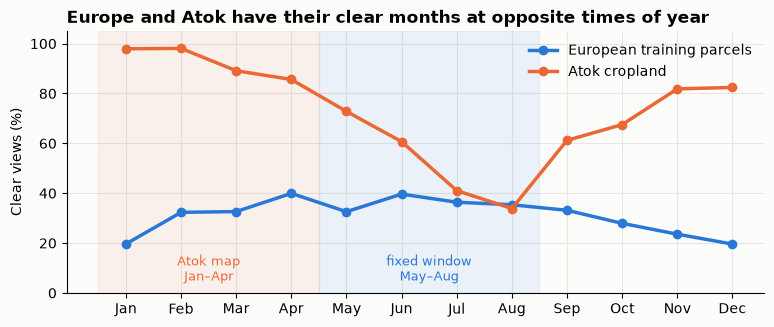

In [10]:
europe = read_csv(features / "observation_loss_by_half_month.csv")
eu_month = {}
for r in europe:
    eu_month.setdefault(int(r["half_month_start"][:2]), []).append(100 * float(r["clear_share"]))
atok = read_csv(land / "monthly_activity.csv")
months = [r["month"] for r in atok]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(months, [np.mean(eu_month[m]) for m in range(1, 13)], color=BLUE, lw=2.5, marker="o", label="European training parcels")
ax.plot(months, [100 * float(r["clear_share_active_cropland"]) for r in atok], color=ORANGE, lw=2.5, marker="o",
        label="Atok cropland")
ax.axvspan(3.5, 7.5, color=BLUE, alpha=.08)
ax.text(5.5, 5, "fixed window\nMay–Aug", ha="center", fontsize=9, color=BLUE)
ax.axvspan(-.5, 3.5, color=ORANGE, alpha=.08)
ax.text(1.5, 5, "Atok map\nJan–Apr", ha="center", fontsize=9, color=ORANGE)
ax.set_ylim(0, 105)
ax.set_ylabel("Clear views (%)")
ax.set_title("Europe and Atok have their clear months at opposite times of year")
ax.legend(frameon=False, loc="upper right")
plt.show()

The European series is the share of clear pixel-dates in the raw Sentinel-2 archive; the Atok series is the
share of cropland pixels clear in each month's half-month composites (Cloud Score+). They are measured
differently, so compare the *shape*, not the levels: Europe's clearest months are spring and summer, while Atok's
rainy season (May–October) is its cloudiest time.

What matters for a four-month window is whether **all eight half-months** are clear at once:

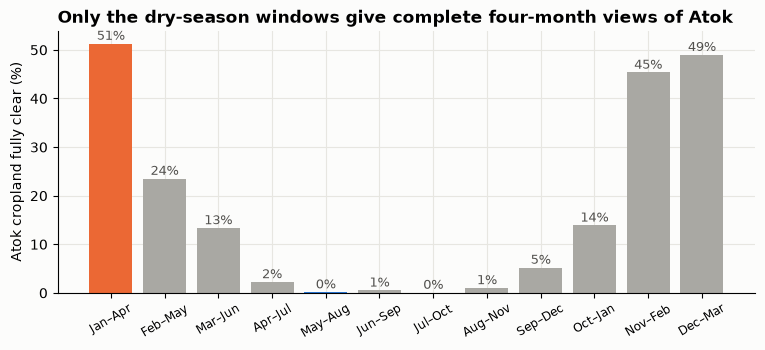

Jan–Apr by year: {'2019': '64%', '2020': '69%', '2021': '50%', '2022': '27%', '2023': '30%', '2024': '100%', '2025': '69%', '2026': '1%'}
May–Aug by year: {'2019': '0%', '2020': '0%', '2021': '0%', '2022': '0%', '2023': '0%', '2024': '1%', '2025': '0%', '2026': '0%'}


In [11]:
windows = read_csv(land / "four_month_windows.csv")
names = list(dict.fromkeys(r["window"] for r in windows))
share = [100 * np.nanmean([float(r["active_cropland_complete_share"]) for r in windows if r["window"] == w]) for w in names]
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(names, share, color=[ORANGE if w == "Jan–Apr" else BLUE if w == "May–Aug" else GREY for w in names])
label_bars(ax, bars, "{:.0f}%")
ax.set_ylabel("Atok cropland fully clear (%)")
ax.set_title("Only the dry-season windows give complete four-month views of Atok")
ax.tick_params(axis="x", labelsize=8.5, rotation=30)
plt.show()
for w in ("Jan–Apr", "May–Aug"):
    by_year = {r["year"]: float(r["active_cropland_complete_share"]) for r in windows if r["window"] == w}
    print(w, "by year:", {y: f"{100 * v:.0f}%" for y, v in by_year.items()})

**This is why the Atok map uses January–April.** In the May–August window almost no Atok cropland is ever fully clear
(averaged over 2019–2026), so a May–August model cannot be applied there at all. The Paoay map therefore uses a
separate fixed model trained on a **January–April** window, applied to 2024, the year with complete
January–April coverage. The price: January–April is early in the European growing year, so that model learns
from fields at an earlier stage than the May–August models.

Atok also does not have one season. Crop cycles start in every month of the year, measured from the same images:

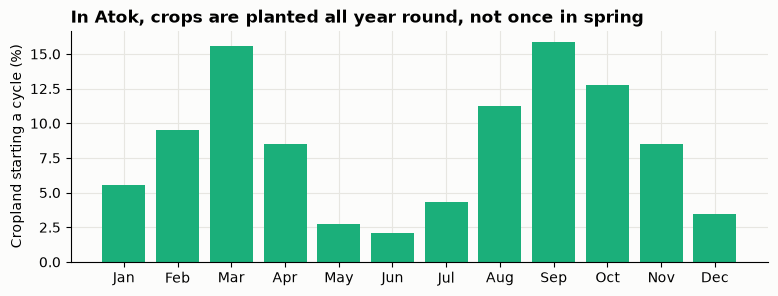

In [12]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(months, [100 * float(r["cycle_start_share"]) for r in atok], color=GREEN)
ax.set_ylabel("Cropland starting a cycle (%)")
ax.set_title("In Atok, crops are planted all year round, not once in spring")
plt.show()

### How the model is trained and chosen

- **Random Forest** with **1,000 trees**: many simple decision trees vote, which copes well with 72 correlated
  numbers and few examples, and needs little tuning.
- Each tree sees a random **half of the training pixels** and, at each split, the **square root** of the 72 numbers
  (about 8). This keeps the trees different from each other, so their vote is more stable.
- **Seed 42** fixes the randomness, so a rerun gives the same model.
- **Weights:** each crop gets the same total weight, and each field the same share within its crop, so the common
  crop or the biggest field does not dominate.
- **Leaf size 2 or 4** (how small a group of pixels a tree may still split) is the only setting chosen, by
  **validation macro-F1**: the average of the three crops' F1 scores, so each crop counts equally.
- A field's prediction is the **average of its pixels' probabilities**.

### How a map pixel is labelled

- A pixel gets a crop only if the model's top probability is at least **0.60** and at least **0.10** above the
  runner-up. Otherwise it is "Unknown crop type": the model is unsure, which is more honest than a forced guess.
- These are illustrative cut-offs, not calibrated probabilities of being right.

In [13]:
from experiments.annual import development_views
from crop_pipeline.sources import adaptive
print("Annual-recipe forest settings:", development_views.FOREST)
print("Label weights:", development_views.LABEL_WEIGHTS)
print("Collection targets per crop:", adaptive.DEFAULT_POLICY["targets"], "| pixels per parcel:",
      adaptive.DEFAULT_POLICY["pixels_per_parcel"], "| seed:", adaptive.DEFAULT_POLICY["seed"])
selection = json.loads((training / "validation/validation_candidates.json").read_text())
print("Leaf size chosen on validation:", {k: v["selected_min_samples_leaf"] for k, v in selection.items()})

Annual-recipe forest settings: {'n_estimators': 1000, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'max_samples': 0.5}
Label weights: {'confirmed': 1.0, 'reported': 0.5}
Collection targets per crop: {'train': {'pixels': 1200, 'parcels': 60}, 'validation': {'pixels': 400, 'parcels': 20}, 'test': {'pixels': 400, 'parcels': 20}} | pixels per parcel: 20 | seed: 42
Leaf size chosen on validation: {'fixed_full': 2, 'aligned_full': 2, 'fixed_matched': 2, 'aligned_matched': 2}


## 5. Experiment 1 — the window models (the reported baseline)

**Why:** this is the main design: does a model trained on European fields recognise the same crops elsewhere?

**How, step by step**

1. Build two kinds of inputs: the **fixed** window (May–August) and the **aligned** window (from green-up).
2. For each, train on all parcels that qualify (**full** cohort) and on only the pixel locations that qualify for
   *both* windows (**matched** cohort). Matched cohorts compare the two windows on exactly the same fields.
3. Pick the leaf size on validation, freeze the four models, and score them once on the external test.
4. Compare with a **baseline that always guesses the most common training crop** (potato). A useful model must
   beat it clearly.

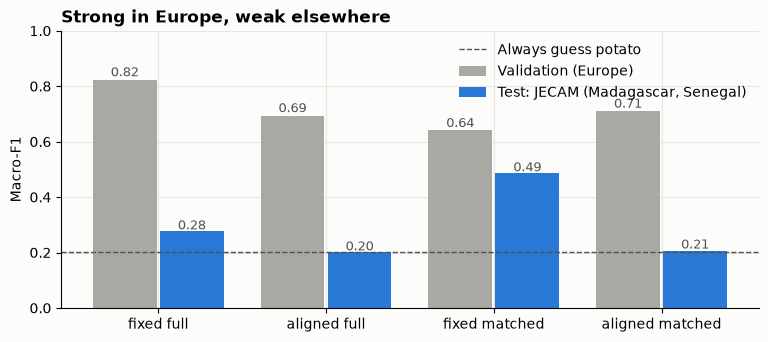

In [14]:
models = ["fixed_full", "aligned_full", "fixed_matched", "aligned_matched"]
validation = {m: json.loads((training / "models" / m / "model_manifest.json").read_text())["validation"]["macro_f1"] for m in models}
jecam = json.loads((testing / "reports/test_scores.json").read_text())
majority = json.loads((testing / "reports/majority_baseline.json").read_text())
x = np.arange(len(models))
fig, ax = plt.subplots(figsize=(9, 3.6))
b1 = ax.bar(x - .2, [validation[m] for m in models], .38, color=GREY, label="Validation (Europe)")
b2 = ax.bar(x + .2, [jecam[m]["macro_f1"] for m in models], .38, color=BLUE, label="Test: JECAM (Madagascar, Senegal)")
label_bars(ax, b1); label_bars(ax, b2)
ax.axhline(majority["fixed_full"]["metrics"]["macro_f1"], color=INK, ls="--", lw=1, label="Always guess potato")
ax.set_xticks(x, [m.replace("_", " ") for m in models])
ax.set_ylim(0, 1)
ax.set_ylabel("Macro-F1")
ax.set_title("Strong in Europe, weak elsewhere")
ax.legend(frameon=False, loc="upper right")
plt.show()

**What it shows:** every model scores well on European validation fields and much worse on JECAM; only the fixed
matched model is clearly above "always guess potato".

**Why validation looks so good:** validation fields come from the same countries, sources and seasons as
training. It is a good check that training worked, but it cannot tell whether the model transfers. That is why the
external test exists, and why **later experiments are judged on the test, not on validation**.

## 6. Experiment 2 — why does it fail? (error analysis)

**Why:** before trying fixes, find the cause. A fix for the wrong cause wastes time.

**How:** every external prediction was joined to its field's pixels, the window used, the date the label was
observed, and its cloud cover. Two findings stand out.

**Finding 1 — the window is in the wrong part of the season.** JECAM labels record when the crop was observed in
the field. The chart shows how often that date falls inside the model's window.

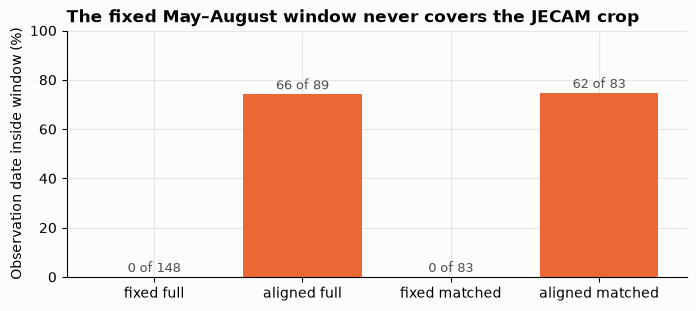

In [15]:
errors = [r for r in read_csv(batch3 / "campaign_crop_errors.csv") if r["population"] == "jecam"]
inside = [sum(int(r["reference_dates_in_window"]) for r in errors if r["model"] == m) for m in models]
total = [sum(int(r["reference_dates_available"]) for r in errors if r["model"] == m) for m in models]
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar([m.replace("_", " ") for m in models], [100 * a / b for a, b in zip(inside, total)],
              color=[BLUE if m.startswith("fixed") else ORANGE for m in models])
for bar, a, b in zip(bars, inside, total):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2, f"{a} of {b}", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 100)
ax.set_ylabel("Observation date inside window (%)")
ax.set_title("The fixed May–August window never covers the JECAM crop")
plt.show()

The fixed window looks at May–August, but the JECAM crops were in the field at other times of year. The model is
classifying a period when the labelled crop was not there. The aligned window covers the observation date about
three times in four, yet it still fails, because so few fields qualify for it and the green-up detector struggles
with year-round cropping.

**Finding 2 — the model's own error estimate is too optimistic.** A Random Forest can estimate its error from the
pixels each tree did not see ("out-of-bag"). But pixels of the same field are almost identical, so a tree that saw
some of a field's pixels has effectively seen the others. Holding out *whole fields* gives the honest figure:

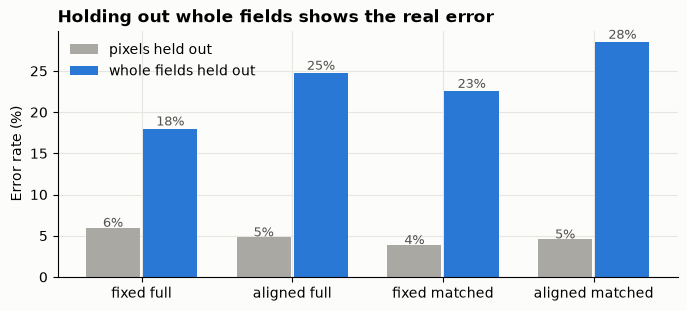

In [16]:
oob = read_csv(batch3 / "oob_summary.csv")
pick = {"pixel_oob": "pixels held out", "whole_parcel_oob": "whole fields held out"}
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (method, label) in enumerate(pick.items()):
    values = [next(100 * float(r["error_rate"]) for r in oob if r["model"] == m and r["method"] == method) for m in models]
    bars = ax.bar(np.arange(4) + (i - .5) * .38, values, .36, color=[GREY, BLUE][i], label=label)
    label_bars(ax, bars, "{:.0f}%")
ax.set_xticks(range(4), [m.replace("_", " ") for m in models])
ax.set_ylabel("Error rate (%)")
ax.set_title("Holding out whole fields shows the real error")
ax.legend(frameon=False)
plt.show()

This is the same reason every experiment below **splits by field, or by place, never by pixel**.

## 7. Experiment 3 — different predictors, and tuning the forest

**Why:** maybe the 72 numbers include ones that only make sense in Europe (for example raw brightness, which
depends on soil and light), or maybe the forest settings are wrong.

**How, step by step**

1. Keep the fields, the split and the forest fixed. Change only the predictors:
   - **one half-month** only (9 numbers): is a single snapshot enough?
   - **bands only** (40) or **indices only** (32): which kind of information transfers?
   - **curve shape** (48): differences between bins, slopes before and after the peak, peak timing and size.
     Describes the *shape* of the season rather than its brightness.
   - **interval + shape** (120): both.
2. Separately, keep the 72 predictors and try five forest settings (leaf size 4 or 8, depth limit 12, more
   features per split), chosen by **geographic folds inside training**: the training fields are grouped by
   one-degree map cells, so each fold is tested on places it did not train on.
3. Freeze every variant and score it once on the same 83 matched JECAM fields.

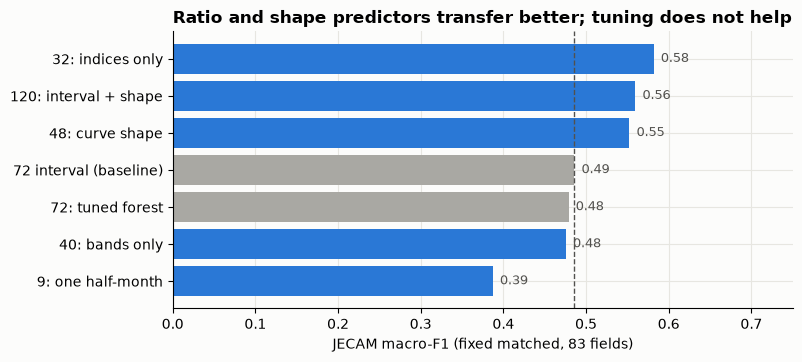

In [17]:
variants = {}
for path in [batch2, batch2 / "shape_comparison", batch2 / "indices_only_comparison", batch2 / "tuned_comparison"]:
    for r in read_csv(path / "comparison_metrics.csv"):
        if r["cohort"] == "fixed_matched" and r["population"] == "jecam" and r["macro_f1"]:
            variants[r["model"]] = float(r["macro_f1"])
names = {"interval_only": "72 interval (baseline)", "single_composite": "9: one half-month", "spectral_bands_only": "40: bands only",
         "indices_only": "32: indices only", "shape_only": "48: curve shape", "interval_and_shape": "120: interval + shape",
         "tuned": "72: tuned forest"}
order = sorted(variants, key=variants.get)
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([names[m] for m in order], [variants[m] for m in order],
               color=[GREY if m in ("interval_only", "tuned") else BLUE for m in order])
label_bars(ax, bars, horizontal=True)
ax.axvline(variants["interval_only"], color=INK, ls="--", lw=1)
ax.set_xlim(0, .75)
ax.set_xlabel("JECAM macro-F1 (fixed matched, 83 fields)")
ax.set_title("Ratio and shape predictors transfer better; tuning does not help")
plt.show()

**What it shows:** indices only, curve shape, and interval + shape beat the baseline on JECAM. The tuned forest does
not. The problem is *what the model is shown*, not how the forest is set up.

**What it means for Atok:** ratio-based predictors (indices) and the season's shape are less tied to European
soils and light, so they are the better building blocks for a place like Atok.

## 8. Experiment 4 — the annual recipe: describe the whole year instead of one window

**Why:** the window models fail mainly on timing (section 6), and Atok has no single season (section 4). A
description of the **whole year** needs no window and no green-up date, so it cannot pick the wrong months.

**How, step by step**

1. Take all 24 half-month composites of a year for each pixel, and fit smooth yearly curves (harmonics) to its
   greenness, moisture and bands. Optionally add **Sentinel-1 radar**, which sees through clouds.
2. Require at least **12 clear half-months** with **no gap longer than three months**, so the curve is not made up.
3. Use the collection-time train/validation lock for all development fields (the window models' split only covers
   fields with a qualifying window).
4. Choose between recipes on **development data only**: spatial folds inside training *and* holding out one whole
   dataset at a time (for example: train on Sen4AgriNet and EuroCrops, test on FranceCrops). The mean of the two is
   the **selection score**, a stand-in for "works on data it has not seen".
5. Freeze each recipe, score it once on the external test, and map Atok.

**The variants tried, and why each one:**

| Variant | Why try it |
| --- | --- |
| A: Sentinel-2 + radar | The main recipe |
| Sentinel-2 only | Does radar add anything? |
| Curve shape B, B + radar, C | Section 6 showed shape transfers well |
| Green-up timing / referenced | Add *when* the crop grows, or measure the curve from green-up instead of 1 January |
| Short-cycle radar (+ S2) | Describe only the strongest four-month radar cycle, for Atok's short cycles |
| Tuned forest, logistic regression, gradient boosting | Same predictors as A, a different learner |

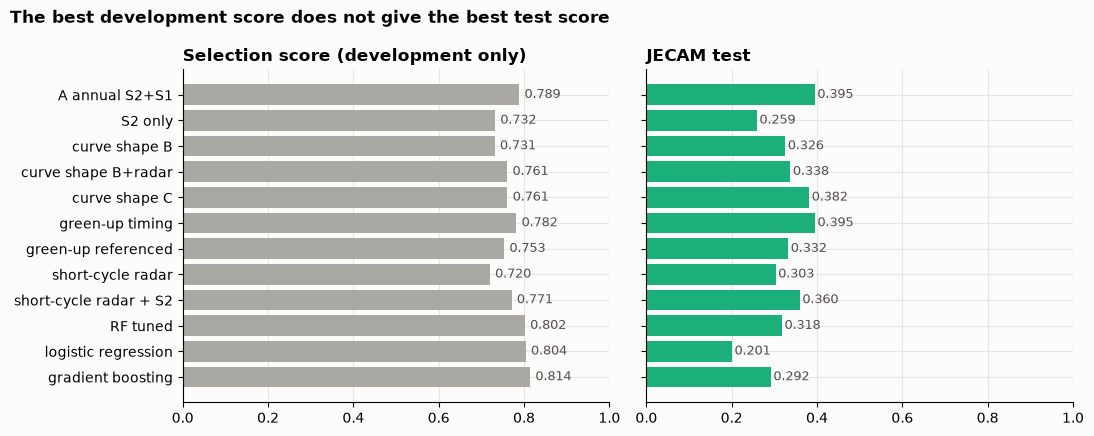

In [18]:
summary = json.loads((experiments / "experiments.json").read_text())["experiments"]
labels = list(summary)
short = [k.split(" (")[0] for k in labels]
select = [summary[k]["development"]["selection_score"] for k in labels]
test = [summary[k]["external"]["jecam"]["macro_f1"] for k in labels]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, values, title, colour in ((axes[0], select, "Selection score (development only)", GREY),
                                  (axes[1], test, "JECAM test", GREEN)):
    bars = ax.barh(short, values, color=colour)
    label_bars(ax, bars, "{:.3f}", horizontal=True)
    ax.set_xlim(0, 1)
    ax.set_title(title)
axes[0].invert_yaxis()
fig.suptitle("The best development score does not give the best test score", x=.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**What it shows:** gradient boosting and logistic regression have the best development scores but are among the
worst on JECAM. Doing well on European data, even on a held-out European dataset, does not predict doing well in
Madagascar or Senegal. The plain recipe A and green-up timing do best on JECAM among the experiments. On the exact
fields the matched window models use, recipe A still trails the fixed matched window model:

In [19]:
comparison = read_csv(root / f"pipeline_outputs/reports/experiments_vs_jose_{testing.name}/model_comparison.csv")
for r in comparison:
    if r["population"] == "jecam" and r["model"] in ("annual experiment (S2 + S1)", "fixed_matched / interval_only (72)"):
        print(f"{r['model']:38} JECAM macro-F1 {float(r['macro_f1']):.3f} on {r['parcels']} shared fields")

fixed_matched / interval_only (72)     JECAM macro-F1 0.486 on 83 shared fields
annual experiment (S2 + S1)            JECAM macro-F1 0.372 on 83 shared fields


## 9. Experiment 5 — add some test-place fields to training, and give them more importance

**Why:** if the problem is that the model has only seen Europe, showing it a few fields from other places should
help. But two questions need care: does it help *only in those places*, and does giving them extra weight make the
model memorise them (overfitting)?

**How, step by step**

1. **Split by place, not by field.** For each test place, whole map blocks of about 10 km × 10 km go either into
   training (**added**) or into the **held-out** half. Neighbouring fields share soil, planting dates and often the
   farmer, so splitting them would leak answers.
2. **Score only the held-out blocks.**
3. **Weight 1×, 2× or 5×:** an added field counts that many times a European field. The weight is chosen by
   block-wise cross-validation *inside the added half*, never by looking at the held-out half.
4. **New place:** train on Europe plus the added blocks of the *other* places, and test on a place left out
   entirely. This is Atok's situation: it has no fields of its own in training.
5. Repeat with **three different block splits**, because which blocks land on each side changes the result.

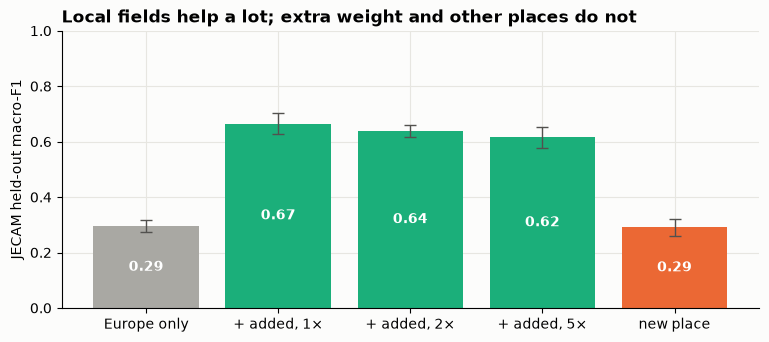

Weight chosen by cross-validation in each split: {'1': 5.0, '2': 2.0, '3': 1.0}
(bars: mean of three splits; whiskers: half the range)


In [20]:
rows = read_csv(mixed / "summary.csv")
show = [("europe_only", "Europe only"), ("europe_plus_added_w1", "+ added, 1×"), ("europe_plus_added_w2", "+ added, 2×"),
        ("europe_plus_added_w5", "+ added, 5×"), ("new_place_chosen_weight", "new place")]
fig, ax = plt.subplots(figsize=(9, 3.6))
means = [np.mean([float(r["macro_f1_jecam"]) for r in rows if r["model"] == m]) for m, _ in show]
spread = [np.ptp([float(r["macro_f1_jecam"]) for r in rows if r["model"] == m]) / 2 for m, _ in show]
bars = ax.bar([l for _, l in show], means, yerr=spread, capsize=4,
              color=[GREY, GREEN, GREEN, GREEN, ORANGE], error_kw={"ecolor": INK, "lw": 1})
label_bars(ax, bars, inside=True)
ax.set_ylim(0, 1)
ax.set_ylabel("JECAM held-out macro-F1")
ax.set_title("Local fields help a lot; extra weight and other places do not")
plt.show()
choice = json.loads((mixed / "experiment.json").read_text())["weight_choice"]
print("Weight chosen by cross-validation in each split:", {seed: v["chosen"] for seed, v in choice.items()})
print("(bars: mean of three splits; whiskers: half the range)")

**What it shows**

- **Same place:** adding fields from Madagascar and Senegal more than doubles the held-out JECAM score. Local
  examples fix the season mismatch.
- **Weight:** cross-validation picked a different weight in each split, and on the held-out fields more weight did
  slightly *worse*. Heavy weight makes the model memorise the added fields instead of learning the place: that is
  overfitting.
- **New place:** no gain. Fields from Madagascar do not teach the model about a place it has never seen.

**What it means for Atok:** fields from other countries will not fix Atok. A small number of **dated, labelled Atok
fields**, added at normal weight (1×), is the most promising step, with some Atok blocks held out to measure the
gain honestly.

## 10. What each approach says about Atok

There are no labels, so instead of accuracy we ask whether each map is **plausible**:

- **Crop mix:** PSA's 2024 statistics for Benguet province give the harvested area of each crop. A province is not
  a municipality, so this is only a rough reference, but a map that is 100% potato is clearly implausible.
- **Confident share:** how much cropland gets a crop at all (the rest is "Unknown").
- **Like the training data?** How much of Atok has predictor values outside what the model saw in training; there,
  the model is extrapolating.

### The crop maps of Paoay

These are the actual crop maps of the Paoay study area, one per approach, at 10 m resolution (each pixel is
0.01 ha). Every pixel inside the study boundary gets carrot, cabbage or potato when the model is confident (top
probability at least 0.60 and at least 0.10 above the next crop); otherwise it is **Unknown crop type**. **No
prediction** means the pixel had too few clear views for that model. Black outlines are the reference areas.

- **Window model, January–April 2024** (Paoay 04): the reported pipeline's map for Atok.
- **Annual recipe A, gradient boosting, short-cycle radar:** experiments, mapped on the whole year 2024.

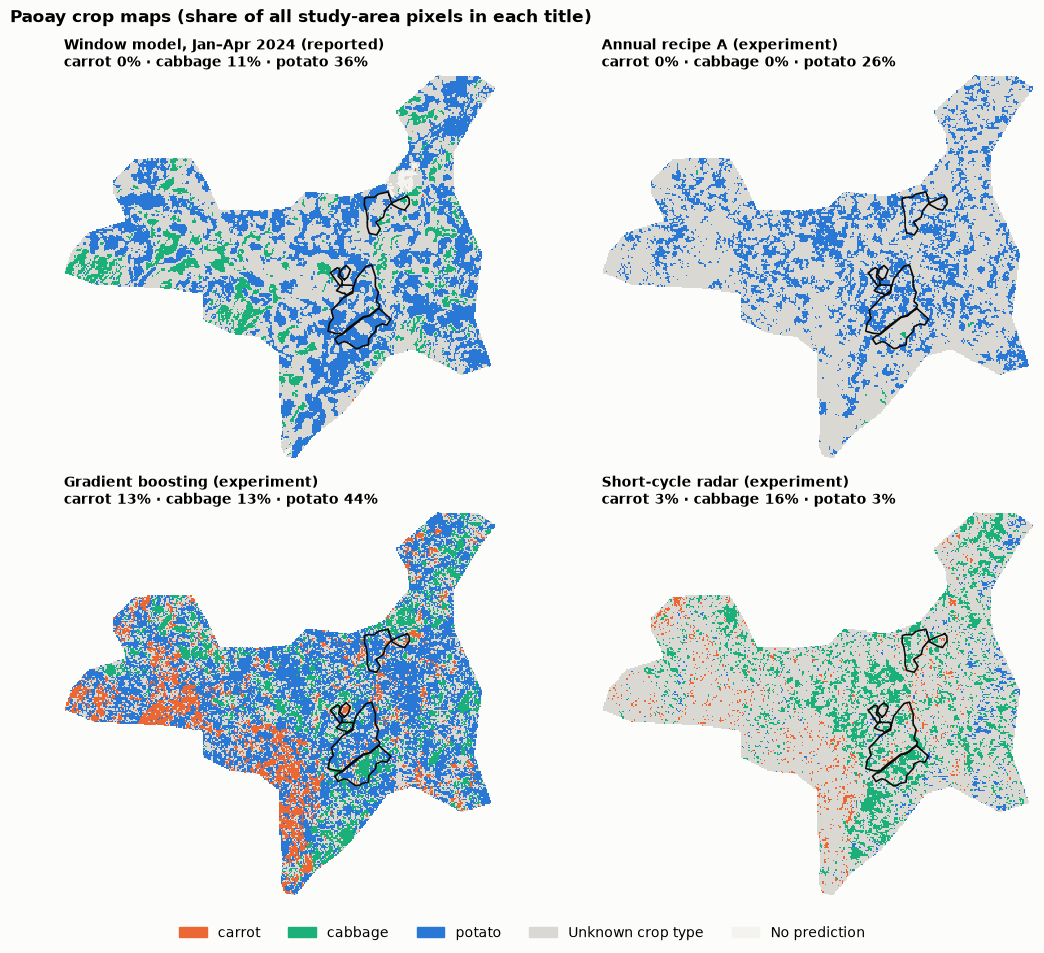

In [21]:
from crop_pipeline.paoay import area_review
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

baseline = resolve_stage_pointer(paoay / "crop_baseline/crop_baseline_stage.json")
maps = [area_review.product("fixed", baseline, name="Window model, Jan–Apr 2024 (reported)")]
for label, title in (("A annual S2+S1", "Annual recipe A (experiment)"),
                     (next(k for k in labels if k.startswith("gradient")), "Gradient boosting (experiment)"),
                     ("short-cycle radar", "Short-cycle radar (experiment)")):
    maps.append(area_review.product("annual", Path(summary[label]["maps"]["paoay"]["run"]), name=title))
if any(m["grid"] != maps[0]["grid"] for m in maps):
    raise ValueError("The Paoay maps use different grids")
map_transform = rasterio.Affine(*maps[0]["grid"]["transform"])

def map_outline(ax, geometry, **style):
    for polygon in getattr(geometry, "geoms", [geometry]):
        c, r = zip(*((~map_transform) * p for p in zip(*polygon.exterior.xy)))
        ax.plot(np.array(c) - .5, np.array(r) - .5, **style)

classes = {1: ("carrot", CROP["carrot"]), 2: ("cabbage", CROP["cabbage"]), 3: ("potato", CROP["potato"]),
           4: ("Unknown crop type", "#d9d8d3"), 5: ("No prediction", "#f4f3ef")}
cmap = ListedColormap([classes[k][1] for k in sorted(classes)])
norm = BoundaryNorm(np.arange(.5, 6), cmap.N)
fig, axes = plt.subplots(2, 2, figsize=(11, 9.6))
for ax, item in zip(axes.flat, maps):
    ax.imshow(np.ma.masked_equal(item["labels"], 0), cmap=cmap, norm=norm, interpolation="nearest")
    for area in areas:
        map_outline(ax, area["geometry"], color="#0b0b0b", lw=1.2)
    mapped = item["labels"] > 0
    crop_share = {classes[k][0]: (item["labels"] == k).sum() / mapped.sum() for k in (1, 2, 3)}
    ax.set_title(item["name"] + "\n" + " · ".join(f"{c} {100 * v:.0f}%" for c, v in crop_share.items()), fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.legend(handles=[Patch(color=c, label=n) for n, c in classes.values()], loc="lower center", ncol=5, frameon=False)
fig.suptitle("Paoay crop maps (share of all study-area pixels in each title)", x=.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, .04, 1, 1))
plt.show()

The same maps as hectares (each pixel is 0.01 ha), for the whole study area and inside the reference areas:

In [22]:
pixel_ha = abs(map_transform.a * map_transform.e) / 1e4
reference_mask = np.zeros(maps[0]["labels"].shape, bool)
for mask in area_review.area_masks(areas, maps[0]["grid"]).values():
    reference_mask |= mask
rows = ["| Map | Area | Carrot ha | Cabbage ha | Potato ha | Unknown ha | No prediction ha |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: |"]
for item in maps:
    for where, mask in (("whole study area", item["labels"] > 0), ("reference areas", reference_mask & (item["labels"] > 0))):
        values = [(item["labels"][mask] == k).sum() * pixel_ha for k in sorted(classes)]
        rows.append(f"| {item['name']} | {where} | " + " | ".join(f"{v:.1f}" for v in values) + " |")
display(Markdown("\n".join(rows)))

| Map | Area | Carrot ha | Cabbage ha | Potato ha | Unknown ha | No prediction ha |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Window model, Jan–Apr 2024 (reported) | whole study area | 0.1 | 43.8 | 148.0 | 217.1 | 2.6 |
| Window model, Jan–Apr 2024 (reported) | reference areas | 0.0 | 0.4 | 11.0 | 11.1 | 0.0 |
| Annual recipe A (experiment) | whole study area | 0.0 | 0.6 | 107.5 | 303.5 | 0.0 |
| Annual recipe A (experiment) | reference areas | 0.0 | 0.1 | 7.5 | 14.8 | 0.0 |
| Gradient boosting (experiment) | whole study area | 52.4 | 54.1 | 179.2 | 126.0 | 0.0 |
| Gradient boosting (experiment) | reference areas | 1.2 | 3.8 | 10.7 | 6.7 | 0.0 |
| Short-cycle radar (experiment) | whole study area | 13.4 | 67.3 | 12.7 | 318.3 | 0.0 |
| Short-cycle radar (experiment) | reference areas | 0.5 | 6.6 | 0.3 | 15.0 | 0.0 |

**Reading the maps:** the window model leaves about half of the area Unknown and calls most of the rest potato,
with cabbage patches mainly in the west. The annual recipe is almost entirely potato or Unknown. Gradient boosting
labels far more of the area and mixes in cabbage and carrot (mostly in the south-west). Short-cycle radar leaves
most of the area Unknown, and most of what it does label is cabbage.
They cannot all be right, and without dated field observations none of them can be checked; the January 2027
field visit is what decides between them.

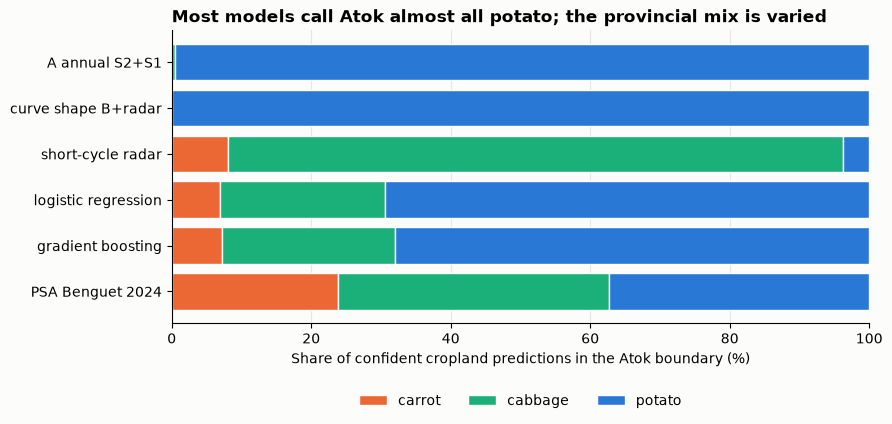

| Map | Confident share of cropland | Outside training range |
| --- | ---: | ---: |
| A annual S2+S1 | 32% | 60% |
| curve shape B+radar | 18% | 4% |
| short-cycle radar | 31% | 76% |
| logistic regression | 79% | 60% |
| gradient boosting | 69% | 60% |

In [23]:
app = {r["map"]: r for r in read_csv(experiments / "application/application_atok.csv")}
reference = json.loads((experiments / "application/province_reference.json").read_text())
chosen = ["A annual S2+S1", "curve shape B+radar", "short-cycle radar"] + [k for k in labels if k.startswith(("logistic", "gradient"))]
names = [k.split(" (")[0] for k in chosen] + ["PSA Benguet 2024"]
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(names))
for crop in CROP:
    values = np.array([float(app[k][f"{crop}_share_of_confident_cropland"]) for k in chosen] + [reference[crop]])
    ax.barh(names, 100 * values, left=100 * left, color=CROP[crop], label=crop, edgecolor="white")
    left += values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of confident cropland predictions in the Atok boundary (%)")
ax.set_title("Most models call Atok almost all potato; the provincial mix is varied")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.2))
plt.show()
table = ["| Map | Confident share of cropland | Outside training range |", "| --- | ---: | ---: |"]
table += [f"| {k.split(' (')[0]} | {100 * float(app[k]['confident_share_of_cropland']):.0f}% | "
          f"{100 * float(app[k]['outside_training_range_share']):.0f}% |" for k in chosen]
display(Markdown("\n".join(table)))

**What it shows**

- The annual recipe and most variants call Atok nearly all potato, which does not fit the provincial mix.
- Short-cycle radar swings to mostly cabbage, but three quarters of Atok is outside its training range.
- Gradient boosting and logistic regression give the most varied, most confident maps, closest to the provincial
  mix, but section 8 showed they are weak on JECAM. A plausible-looking map is not proof of a correct one.
- The window model's January–April map covers only the Paoay study area (printed below; see the pipeline guide,
  stage 05).

In [24]:
for r in read_csv(experiments / "application/application_paoay.csv"):
    if r["map"].startswith("window model: fixed"):
        mix = " / ".join(f"{c} {100 * float(r[c + '_share_of_confident_cropland']):.0f}%" for c in CROP)
        print(f"{r['map']}: confident on {100 * float(r['confident_share_of_cropland']):.0f}% of cropland; {mix}")

window model: fixed Jan-Apr (Paoay 04): confident on 48% of cropland; carrot 0% / cabbage 9% / potato 91%


## 11. Summary: what we learned and what to do next

| Experiment | Question | Answer |
| --- | --- | --- |
| Window models | Does a European model work elsewhere? | Strong on European validation, weak on JECAM |
| Error analysis | Why not? | Wrong part of the season; pixel-level checks hide it |
| Predictors and tuning | Would other inputs or settings help? | Index and shape predictors help a little; tuning does not |
| Annual recipe | Does a whole-year description avoid the timing problem? | Partly; similar to the best window models, and Atok maps are mostly potato |
| Mixed training | Do labels from the test places help? | A lot in those places, nothing in a new place; extra weight overfits |
| Atok checks | Are the maps plausible? | Most are too potato-heavy; the more varied ones are weaker on JECAM |

**The main lesson:** the gap is about **place and season**, not the classifier. Changing the learner, the settings or
the predictors moves scores a little; local examples move them a lot.

**For Atok, step by step:**

1. Run the January 2027 field visit (Paoay 05): record dated crop observations with GPS, without looking at the map
   first.
2. Compare the frozen maps (the window model's January–April map and the gradient-boosting experiment) against those
   observations. This is the first honest local test.
3. Add a share of the labelled Atok fields to training at normal weight, keeping whole Atok blocks held out, and
   measure the gain on those blocks, exactly as in section 9.
4. Keep the map's Unknown class and the land-use and calendar checks: they show where the model is unsure or out of
   its depth.